In [23]:
import pandas as pd

df = pd.read_csv("sensor_readings_4.data", header=None,
                 names=["front", "left", "right", "back", "action"])
print(df.head())
print(df["action"].value_counts())
print(df.describe())

   front   left  right   back             action
0  1.687  0.445  2.332  0.429  Slight-Right-Turn
1  1.687  0.449  2.332  0.429  Slight-Right-Turn
2  1.687  0.449  2.334  0.429  Slight-Right-Turn
3  1.687  0.449  2.334  0.429  Slight-Right-Turn
4  1.687  0.449  2.334  0.429  Slight-Right-Turn
action
Move-Forward         2205
Sharp-Right-Turn     2097
Slight-Right-Turn     826
Slight-Left-Turn      328
Name: count, dtype: int64
             front         left        right         back
count  5456.000000  5456.000000  5456.000000  5456.000000
mean      1.290307     0.681269     1.881819     1.273689
std       0.626700     0.342594     0.562533     0.821750
min       0.495000     0.340000     0.836000     0.367000
25%       0.826000     0.495000     1.472000     0.788000
50%       1.089500     0.612000     1.753000     1.066500
75%       1.519500     0.753000     2.139000     1.400500
max       5.000000     5.000000     5.000000     5.000000


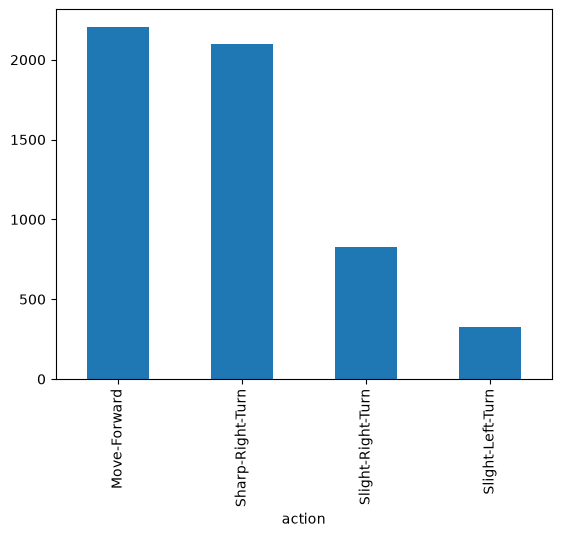

In [24]:
import matplotlib.pyplot as plt
df["action"].value_counts().plot(kind="bar")
plt.show()

In [25]:
# 1) Train / test split
split = int(len(df) * 0.75)
train, test = df[:split].copy(), df[split:].copy()

sensors = ["front", "left", "right", "back"]

# 2) Per Sensor thresholds using TRAIN 
thresholds = {}
for s in sensors:
    q1, q2 = train[s].quantile([0.33, 0.66])
    thresholds[s] = (q1, q2)
    print(s, "-> Near <", round(q1, 3), "| Medium <", round(q2, 3), "Far")

# 3) Number label  function
def to_label(value, q1, q2):
    if value < q1:
        return "Near"
    elif value < q2:
        return "Medium"
    else:
        return "Far"

# 4) Train aur test 
for s in sensors:
    q1, q2 = thresholds[s]
    train[s + "_d"] = train[s].apply(lambda v: to_label(v, q1, q2))
    test[s + "_d"] = test[s].apply(lambda v: to_label(v, q1, q2))

# 5) Check karo
print(train[["front", "front_d", "left", "left_d"]].head())
print(train["front_d"].value_counts())

front -> Near < 0.87 | Medium < 1.366 Far
left -> Near < 0.522 | Medium < 0.7 Far
right -> Near < 1.588 | Medium < 1.935 Far
back -> Near < 0.88 | Medium < 1.262 Far
   front front_d   left left_d
0  1.687     Far  0.445   Near
1  1.687     Far  0.449   Near
2  1.687     Far  0.449   Near
3  1.687     Far  0.449   Near
4  1.687     Far  0.449   Near
front_d
Far       1393
Medium    1355
Near      1344
Name: count, dtype: int64


In [26]:
import pandas as pd

actions = sorted(train["action"].unique())
levels = ["Near", "Medium", "Far"]

# 1) Prior
prior = train["action"].value_counts(normalize=True)
print("PRIOR:")
print(prior.round(3))

# 2) Likelihood
likelihood = {}
for s in sensors:
    likelihood[s] = {}
    for a in actions:
        rows_a = train[train["action"] == a]
        counts = rows_a[s + "_d"].value_counts()
        total = len(rows_a)
        likelihood[s][a] = {}
        for lv in levels:
            likelihood[s][a][lv] = (counts.get(lv, 0) + 1) / (total + 3)

# 3) Left sensor 
print("\nLEFT sensor likelihood:")
print(pd.DataFrame(likelihood["left"]).round(3))

PRIOR:
action
Move-Forward         0.403
Sharp-Right-Turn     0.383
Slight-Right-Turn    0.159
Slight-Left-Turn     0.054
Name: proportion, dtype: float64

LEFT sensor likelihood:
        Move-Forward  Sharp-Right-Turn  Slight-Left-Turn  Slight-Right-Turn
Near           0.094             0.348             0.004              0.997
Medium         0.564             0.263             0.004              0.002
Far            0.342             0.389             0.991              0.002


In [27]:
import numpy as np

def predict_proba(evidence):
    # evidence = {"front": "Near", "left": "Far", "right": "Medium", "back": "Far"}
    log_scores = {}
    for a in actions:
        score = np.log(prior[a])
        for s in sensors:
            score += np.log(likelihood[s][a][evidence[s]])
        log_scores[a] = score
    m = max(log_scores.values())
    exp = {a: np.exp(v - m) for a, v in log_scores.items()}
    total = sum(exp.values())
    return {a: round(v / total, 3) for a, v in exp.items()}

# Example
print(predict_proba({"front": "Far", "left": "Near", "right": "Far", "back": "Medium"}))

# all test data per accuracy
preds = []
for _, row in test.iterrows():
    ev = {s: row[s + "_d"] for s in sensors}
    p = predict_proba(ev)
    preds.append(max(p, key=p.get))
test["pred"] = preds

acc = (test["pred"] == test["action"]).mean()
print("Model accuracy:", round(acc * 100, 2), "%")

baseline = test["action"].value_counts(normalize=True).max()
print("Baseline (Normal Action tell):", round(baseline * 100, 2), "%")

{'Move-Forward': np.float64(0.09), 'Sharp-Right-Turn': np.float64(0.0), 'Slight-Left-Turn': np.float64(0.0), 'Slight-Right-Turn': np.float64(0.909)}
Model accuracy: 90.03 %
Baseline (Normal Action tell): 40.62 %


                   precision    recall  f1-score   support

     Move-Forward       0.96      0.81      0.88       554
 Sharp-Right-Turn       0.99      0.95      0.97       528
 Slight-Left-Turn       0.65      1.00      0.79       107
Slight-Right-Turn       0.76      1.00      0.87       175

         accuracy                           0.90      1364
        macro avg       0.84      0.94      0.87      1364
     weighted avg       0.92      0.90      0.90      1364

Model ne bola      Move-Forward  Sharp-Right-Turn  Slight-Left-Turn  \
Asli                                                                  
Move-Forward                446                 6                49   
Sharp-Right-Turn             19               500                 8   
Slight-Left-Turn              0                 0               107   
Slight-Right-Turn             0                 0                 0   

Model ne bola      Slight-Right-Turn  
Asli                                  
Move-Forward        

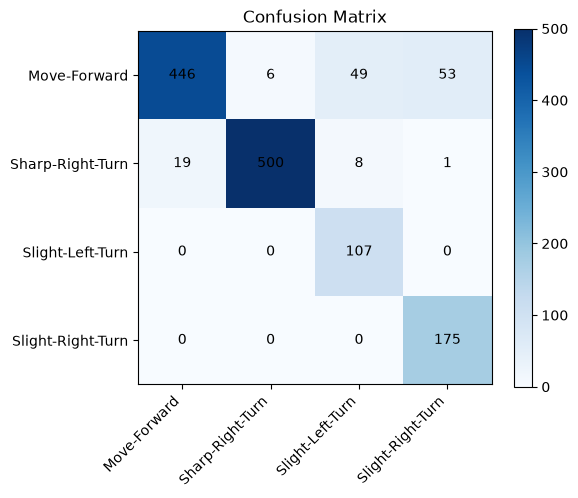

In [28]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# 1) Per action different score
print(classification_report(test["action"], test["pred"]))

# 2) Confusion matrix
cm = pd.crosstab(test["action"], test["pred"],
                 rownames=["Asli"], colnames=["Model ne bola"])
cm = cm.reindex(index=actions, columns=actions, fill_value=0)
print(cm)

# 3) Picture
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(cm.columns)), cm.columns, rotation=45, ha="right")
plt.yticks(range(len(cm.index)), cm.index)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm.iloc[i, j], ha="center", va="center")
plt.colorbar()
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
def run_model(n_bins, train, test, sensors, drop=None):
    tr, te = train.copy(), test.copy()
    qs = [i / n_bins for i in range(1, n_bins)]

    # discretization: train cuts find
    for s in sensors:
        cuts = train[s].quantile(qs).values
        tr[s + "_d"] = np.digitize(tr[s], cuts)
        te[s + "_d"] = np.digitize(te[s], cuts)

    acts = sorted(tr["action"].unique())
    pri = tr["action"].value_counts(normalize=True)
    used = [s for s in sensors if s != drop]   # drop = koi sensor hataana ho to

    # likelihood
    lik = {}
    for s in used:
        lik[s] = {}
        for a in acts:
            sub = tr[tr["action"] == a][s + "_d"]
            counts = sub.value_counts()
            lik[s][a] = {b: (counts.get(b, 0) + 1) / (len(sub) + n_bins)
                         for b in range(n_bins)}

    # prediction
    correct = 0
    for _, row in te.iterrows():
        best, best_score = None, -1e18
        for a in acts:
            sc = np.log(pri[a]) + sum(np.log(lik[s][a][row[s + "_d"]]) for s in used)
            if sc > best_score:
                best, best_score = a, sc
        correct += (best == row["action"])
    return correct / len(te)

for n in [2, 3, 4, 5, 7, 10]:
    acc = run_model(n, train, test, sensors)
    print(n, "bins ->", round(acc * 100, 2), "%")

2 bins -> 75.66 %
3 bins -> 90.18 %
4 bins -> 86.88 %
5 bins -> 91.28 %
7 bins -> 93.48 %
10 bins -> 95.89 %


In [30]:
k = int(len(train) * 0.8)
sub_train, val = train[:k], train[k:]


results = {}
for n in [3, 5, 7, 10, 15, 20, 30]:
    results[n] = run_model(n, sub_train, val, sensors)
    print(n, "bins -> validation accuracy:", round(results[n] * 100, 2), "%")

best_n = max(results, key=results.get)
print("\nBetter bins:", best_n)

# Ab TEST par sirf ek baar, poore train se
final = run_model(best_n, train, test, sensors)
print("FINAL test accuracy:", round(final * 100, 2), "%")

3 bins -> validation accuracy: 85.47 %
5 bins -> validation accuracy: 89.87 %
7 bins -> validation accuracy: 92.8 %
10 bins -> validation accuracy: 94.99 %
15 bins -> validation accuracy: 94.87 %
20 bins -> validation accuracy: 94.87 %
30 bins -> validation accuracy: 96.46 %

Better bins: 30
FINAL test accuracy: 96.77 %


In [31]:
n = 10
base = run_model(n, train, test, sensors)
print("with all sensors:", round(base * 100, 2), "%\n")

for s in sensors:
    acc = run_model(n, train, test, sensors, drop=s)
    print("without", s, "->", round(acc * 100, 2), "%   (donwfall:", round((base - acc) * 100, 2), "points)")

with all sensors: 95.89 %

without front -> 69.13 %   (donwfall: 26.76 points)
without left -> 88.71 %   (donwfall: 7.18 points)
without right -> 96.26 %   (donwfall: -0.37 points)
without back -> 95.97 %   (donwfall: -0.07 points)


In [32]:
import json

def build_model(n_bins, train, sensors):
    qs = [i / n_bins for i in range(1, n_bins)]
    cuts = {s: [float(c) for c in train[s].quantile(qs).values] for s in sensors}
    tr = train.copy()
    for s in sensors:
        tr[s + "_d"] = np.digitize(tr[s], cuts[s])
    acts = sorted(tr["action"].unique())
    prior = {a: float((tr["action"] == a).mean()) for a in acts}
    lik = {}
    for s in sensors:
        lik[s] = {}
        for a in acts:
            sub = tr[tr["action"] == a][s + "_d"]
            counts = sub.value_counts()
            lik[s][a] = [float((counts.get(b, 0) + 1) / (len(sub) + n_bins))
                         for b in range(n_bins)]
    return {"n_bins": n_bins, "sensors": sensors, "actions": acts,
            "cuts": cuts, "prior": prior, "likelihood": lik}

model = build_model(10, train, sensors)
with open("model.json", "w") as f:
    json.dump(model, f, indent=2)


def predict_from_json(m, reading):
    scores = {}
    for a in m["actions"]:
        sc = np.log(m["prior"][a])
        for s in m["sensors"]:
            b = int(np.digitize(reading[s], m["cuts"][s]))
            sc += np.log(m["likelihood"][s][a][b])
        scores[a] = sc
    return max(scores, key=scores.get)

preds = [predict_from_json(model, row) for _, row in test[sensors].iterrows()]
print("JSON model accuracy:", round((np.array(preds) == test["action"].values).mean() * 100, 2), "%")


JSON model accuracy: 95.89 %
